<a href="https://colab.research.google.com/github/Karolina-Dem/useful_programs/blob/main/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro



In [22]:
# Obliczenie 2+2
wynik_dodawania = 2 + 2
print("Wynik działania 2 + 2 =", wynik_dodawania)

Wynik działania 2 + 2 = 4


In [23]:
import math
# Obliczenie pi^pi
wynik_potegowania = math.pi ** math.pi
print("Wynik działania pi^pi =", wynik_potegowania)

Wynik działania pi^pi = 36.4621596072079


## Obliczenia matematyczne: Ciąg geometryczny

Suma pierwszych $n$ wyrazów ciągu geometrycznego, gdzie $a_1$ to pierwszy wyraz, a $q$ to iloraz ciągu ($q \neq 1$), wyraża się wzorem:

$$S_n = a_1 \frac{1-q^n}{1-q}$$

Jeżeli $|q| < 1$, to przy $n \to \infty$ suma ta dąży do granicy (sumy szeregu geometrycznego):

$$S = \frac{a_1}{1-q}$$

In [24]:
# Komórka kodu licząca sumę kwadratów liczb od 1 do 100
suma_kwadratow_wyliczona = sum(i**2 for i in range(1, 101))
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow_wyliczona}")

Suma kwadratów liczb od 1 do 100 wynosi: 338350


In [25]:
import os
# Komórka kodu zapisująca wynik sumy kwadratów do pliku colab_wynik.txt
with open("colab_wynik.txt", "w") as f:
    f.write(str(suma_kwadratow_wyliczona))

print(f"Wynik został pomyślnie zapisany w pliku: {os.path.abspath('colab_wynik.txt')}")

Wynik został pomyślnie zapisany w pliku: /content/colab_wynik.txt


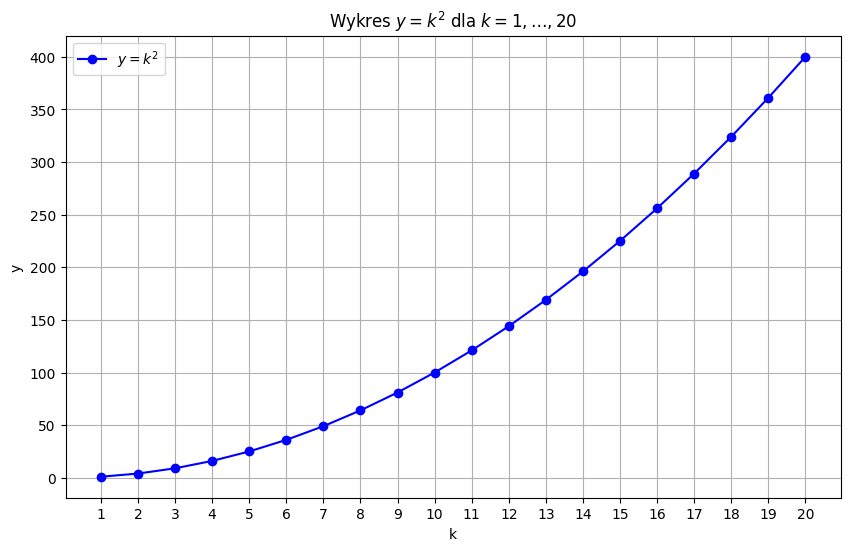

Zapisano wykres pod ścieżką: /content/wykres.png


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Tworzenie wykresu y = k^2 dla k = 1, ..., 20
k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label=r'$y = k^2$')
plt.title(r'Wykres $y = k^2$ dla $k = 1, …, 20$')
plt.xlabel('k')
plt.ylabel('y')
plt.xticks(k)
plt.grid(True)
plt.legend()

# Zapis wykresu do pliku wykres.png
out_path = "wykres.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

print("Zapisano wykres pod ścieżką:", os.path.abspath(out_path))

In [27]:
### Animacja Wahadła
Poniższa komórka tworzy animację wahadła w formacie MP4 przy użyciu `matplotlib` i zapisuje ją do pliku `video.mp4`.

SyntaxError: invalid syntax (1483573694.py, line 2)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Zapisano animację MP4: /content/video.mp4


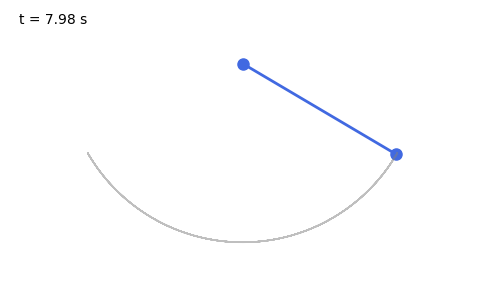

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import os

# 1) Instalacja narzędzia ffmpeg, jeśli jest wymagane
!apt-get update -qq && apt-get install -y ffmpeg > /dev/null 2>&1

# 2) Parametry fizyczne wahadła
L = 1.0
g = 9.81
dt = 0.02
t_max = 8.0
t = np.arange(0, t_max, dt)

theta0 = np.pi / 3
omega = np.sqrt(g / L)
theta = theta0 * np.cos(omega * t)

x = L * np.sin(theta)
y = -L * np.cos(theta)

# 3) Przygotowanie wykresu pod animację
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect('equal')
ax.axis('off')

rod, = ax.plot([], [], 'o-', lw=2, color='royalblue', markersize=8)
trail, = ax.plot([], [], '-', lw=1, color='gray', alpha=0.5)
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes)

def init():
    rod.set_data([], [])
    trail.set_data([], [])
    time_text.set_text('')
    return rod, trail, time_text

def update(frame):
    i = frame
    rod.set_data([0, x[i]], [0, y[i]])
    trail.set_data(x[:i+1], y[:i+1])
    time_text.set_text(f't = {t[i]:.2f} s')
    return rod, trail, time_text

ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True, interval=20)

# 4) Zapisanie animacji do pliku video.mp4
video_path = "video.mp4"
ani.save(video_path, writer='ffmpeg', fps=30)
print("Zapisano animację MP4:", os.path.abspath(video_path))

# 5) Osadzenie wideo w notebooku
mp4 = open(video_path, 'rb').read()
display(HTML(f'''
<video width="420" height="420" controls autoplay loop>
  <source src="data:video/mp4;base64,{mp4.hex()}" type="video/mp4">
</video>
'''))

In [29]:
### Konwersja MP4 do GIF
Generujemy animowany plik `video.gif` na podstawie wcześniej przygotowanego pliku wideo.

SyntaxError: invalid syntax (3015818477.py, line 2)

In [30]:
from moviepy.editor import VideoFileClip
import os

video_path = "video.mp4"
gif_path = "video.gif"

if os.path.exists(video_path):
    clip = VideoFileClip(video_path)
    clip.write_gif(gif_path, fps=15, program='ffmpeg')
    clip.close()
    print("Zapisano animowany GIF pod ścieżką:", os.path.abspath(gif_path))
else:
    print(f"Błąd: Plik {video_path} nie istnieje!")

MoviePy - Building file  video.gif
MoviePy - - Generating GIF frames.


MoviePy - - File ready: video.gif.
Zapisano animowany GIF pod ścieżką: /content/video.gif


In [31]:
### Wykres Własnej Krzywej Parametrycznej
Generujemy zmodyfikowaną krzywą parametryczną w 3D (helisę) i zapisujemy ją jako plik graficzny `parametric_curve.png`.

SyntaxError: invalid decimal literal (1164978595.py, line 2)

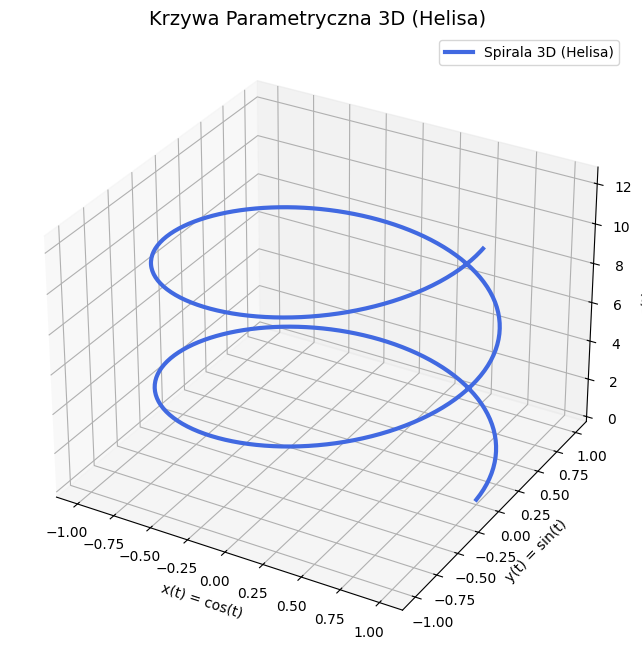

Zapisano wykres krzywej parametrycznej do: /content/parametric_curve.png


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

# Zdefiniowanie równań parametrycznych krzywej 3D (Helisa)
t = np.linspace(0, 4 * np.pi, 500)
x = np.cos(t)
y = np.sin(t)
z = t

# Tworzenie wykresu 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Spirala 3D (Helisa)", color="royalblue", linewidth=3)
ax.set_title("Krzywa Parametryczna 3D (Helisa)", fontsize=14)
ax.set_xlabel("x(t) = cos(t)")
ax.set_ylabel("y(t) = sin(t)")
ax.set_zlabel("z(t) = t")
ax.legend()

# Zapis do pliku
out_curve_path = "parametric_curve.png"
plt.savefig(out_curve_path, dpi=150, bbox_inches='tight')
plt.show()

print("Zapisano wykres krzywej parametrycznej do:", os.path.abspath(out_curve_path))

---

### Podsumowanie i Koniec Notebooka

In [11]:
# Komórka kodu licząca sumę kwadratów liczb od 1 do 100
suma_kwadratow = sum(i**2 for i in range(1, 101))
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}")

Suma kwadratów liczb od 1 do 100 wynosi: 338350


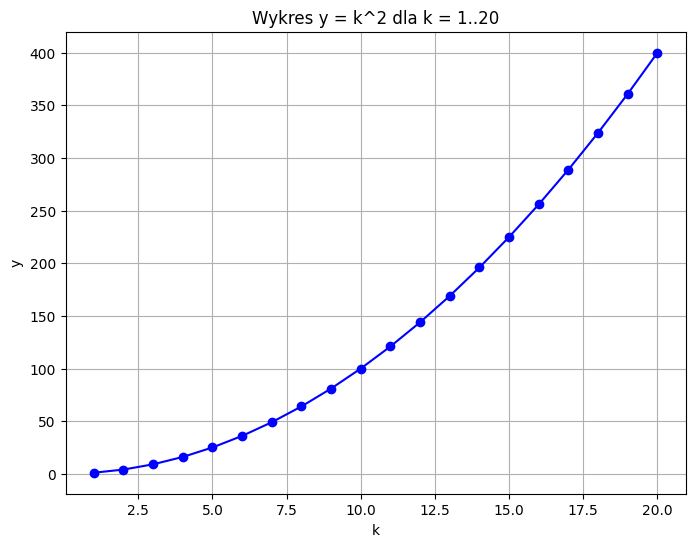

In [12]:
import matplotlib.pyplot as plt

k = list(range(1, 21))
y = [x**2 for x in k]

plt.figure(figsize=(8, 6))
plt.plot(k, y, marker='o', linestyle='-', color='blue')
plt.title("Wykres y = k^2 dla k = 1..20")
plt.xlabel("k")
plt.ylabel("y")
plt.grid(True)
plt.savefig("wykres.png", dpi=150, bbox_inches="tight")
plt.show()

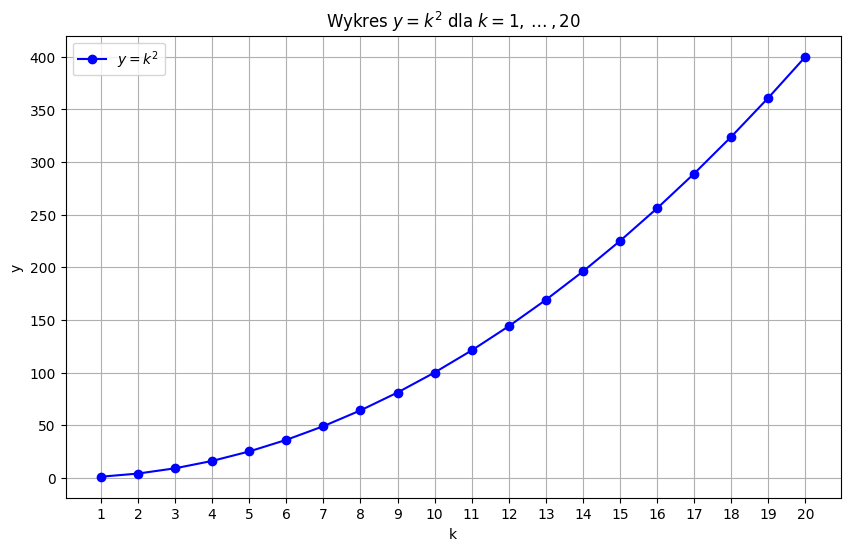

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Definiowanie wartości k od 1 do 20
k = np.arange(1, 21)
y = k**2

# Tworzenie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label=r'$y = k^2$')

# Dodanie etykiet i tytułu z poprawnym r-stringiem dla LaTeX
plt.title(r'Wykres $y = k^2$ dla $k = 1, \dots, 20$')
plt.xlabel('k')
plt.ylabel('y')
plt.xticks(k)
plt.grid(True)
plt.legend()

# Zapis wykresu do pliku
plt.savefig("wykres.png", dpi=150, bbox_inches="tight")

# Wyświetlenie wykresu
plt.show()

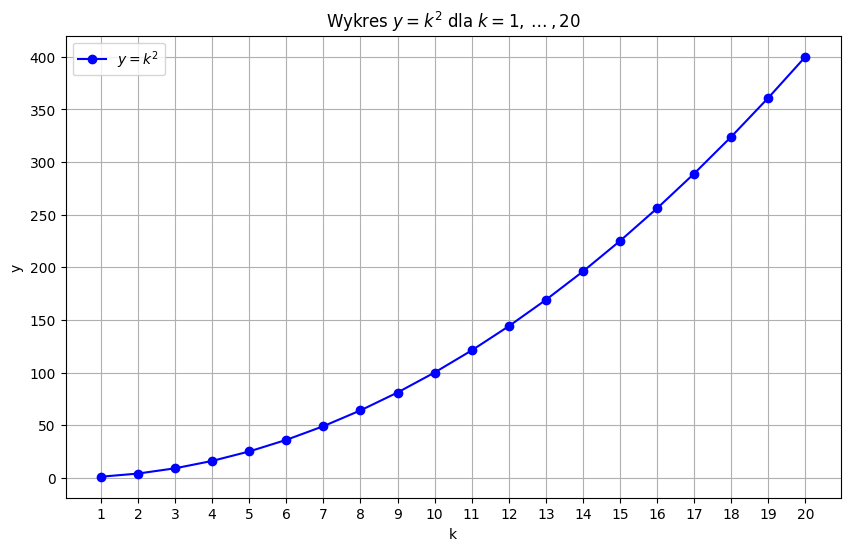

Zapisano: /content/wykres.png


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Definiowanie wartości k od 1 do 20
k = np.arange(1, 21)
y = k**2

# Tworzenie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label=r'$y = k^2$')

# Etykiety i wygląd
plt.title(r'Wykres $y = k^2$ dla $k = 1, \dots, 20$')
plt.xlabel('k')
plt.ylabel('y')
plt.xticks(k)
plt.grid(True)
plt.legend()

# Zapis wykresu do pliku PRZED pokazaniem
out_path = "wykres.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

# Potwierdzenie, że plik istnieje
print("Zapisano:", os.path.abspath(out_path))

In [15]:
from google.colab import files
print("Przygotowano moduł do pobierania plików lokalnych.")

Przygotowano moduł do pobierania plików lokalnych.


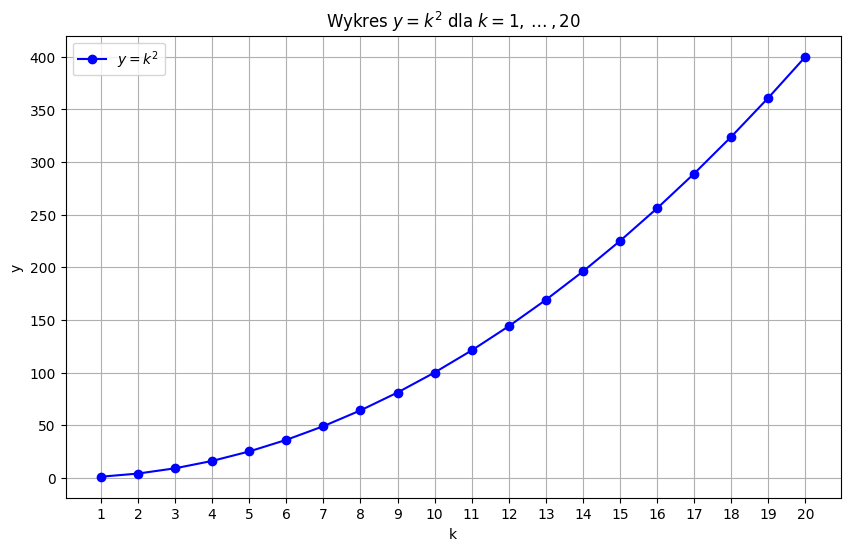

Zapisano lokalnie jako: /content/wykres.png
Rozpoczynam pobieranie pliku na Twój komputer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label=r'$y = k^2$')
plt.title(r'Wykres $y = k^2$ dla $k = 1, \dots, 20$')
plt.xlabel('k')
plt.ylabel('y')
plt.xticks(k)
plt.grid(True)
plt.legend()

# Zapisujemy lokalnie w katalogu roboczym
out_path = "wykres.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Zapisano lokalnie jako: {os.path.abspath(out_path)}")
print("Rozpoczynam pobieranie pliku na Twój komputer...")
files.download(out_path)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Zapisano: /content/video.mp4
Rozmiar MP4: 127494


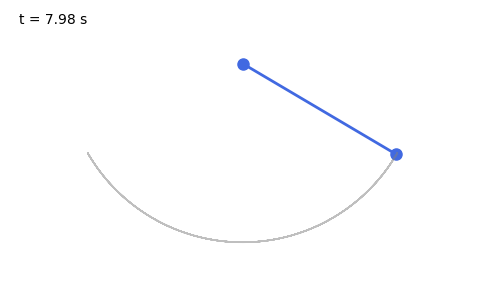

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import os

# 1) zainstaluj ffmpeg, jeśli go nie ma
!apt-get update -qq
!apt-get install -y ffmpeg > /dev/null 2>&1

# 2) parametry wahadła
L = 1.0
g = 9.81
dt = 0.02
t_max = 8.0
t = np.arange(0, t_max, dt)

theta0 = np.pi / 3
omega = np.sqrt(g / L)
theta = theta0 * np.cos(omega * t)

x = L * np.sin(theta)
y = -L * np.cos(theta)

# 3) przygotowanie wykresu
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect('equal')
ax.axis('off')

rod, = ax.plot([], [], 'o-', lw=2, color='royalblue', markersize=8)
trail, = ax.plot([], [], '-', lw=1, color='gray', alpha=0.5)
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes)

def init():
    rod.set_data([], [])
    trail.set_data([], [])
    time_text.set_text('')
    return rod, trail, time_text

def update(frame):
    i = frame
    rod.set_data([0, x[i]], [0, y[i]])
    trail.set_data(x[:i+1], y[:i+1])
    time_text.set_text(f't = {t[i]:.2f} s')
    return rod, trail, time_text

ani = FuncAnimation(
    fig,
    update,
    frames=len(t),
    init_func=init,
    blit=True,
    interval=20
)

# 4) zapis do video.mp4
video_path = "video.mp4"
ani.save(video_path, writer='ffmpeg', fps=30)
print("Zapisano:", os.path.abspath(video_path))

# 5) wyświetlenie w notebooku
mp4 = open(video_path, 'rb').read()
print("Rozmiar MP4:", len(mp4))
display(HTML(f"""
<video width="420" height="420" controls autoplay loop>
  <source src="data:video/mp4;base64,{mp4.hex()}" type="video/mp4">
</video>
"""))

### Konwersja animacji z MP4 do formatu GIF
Poniższa komórka wczytuje wygenerowany wcześniej plik `video.mp4` i konwertuje go na animowany plik `video.gif` przy użyciu biblioteki `moviepy`.

In [18]:
from moviepy.editor import VideoFileClip
import os

video_path = "video.mp4"
gif_path = "video.gif"

# Upewniamy się, czy plik MP4 na pewno istnieje przed konwersją
if os.path.exists(video_path):
    clip = VideoFileClip(video_path)
    clip.write_gif(gif_path, fps=15, program='ffmpeg')
    clip.close()
    print("Zapisano animowany GIF pod ścieżką:", os.path.abspath(gif_path))
else:
    print(f"Błąd: Plik {video_path} nie istnieje! Uruchom najpierw komórkę generującą animację wahadła (cell -QCZwp1jODV2).")

/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':

  from pkg_resources import resource_stream, resource_exists



MoviePy - Building file  video.gif
MoviePy - - Generating GIF frames.


MoviePy - - File ready: video.gif.
Zapisano animowany GIF pod ścieżką: /content/video.gif


### Generowanie i zapisywanie własnej krzywej parametrycznej
Poniższy kod generuje klasyczną krzywą parametryczną (np. spiralę Fermata lub trójlistnik/rozetę). Wynik zostaje wyświetlony na wykresie oraz zapisany jako plik graficzny `parametric_curve.png`.

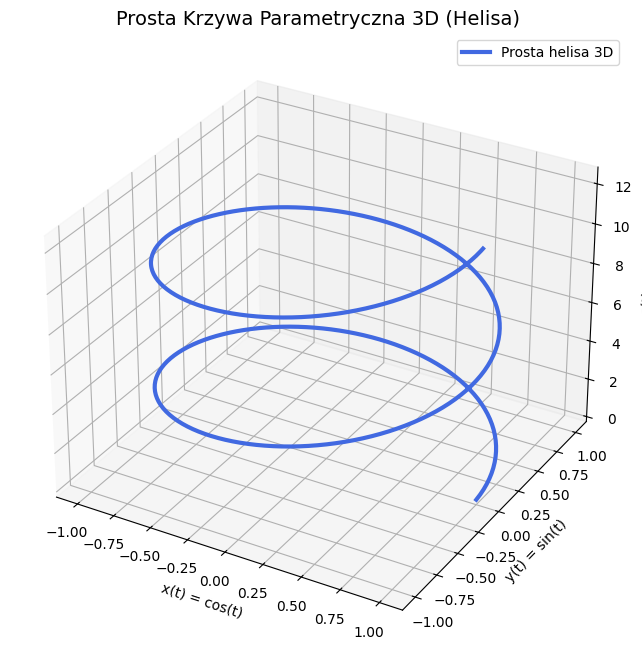

Zapisano prostą trójwymiarową krzywą parametryczną jako: /content/parametric_curve.png


In [19]:
# Correcting the label for rendering issue in matplotlib mathtext
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

# Parametric equations - prosta trójwymiarowa helisa (spirala)
t = np.linspace(0, 4 * np.pi, 500)
x = np.cos(t)
y = np.sin(t)
z = t

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Prosta helisa 3D", color="royalblue", linewidth=3)
ax.set_title("Prosta Krzywa Parametryczna 3D (Helisa)", fontsize=14)
ax.set_xlabel("x(t) = cos(t)")
ax.set_ylabel("y(t) = sin(t)")
ax.set_zlabel("z(t) = t")
ax.legend()

# Zapis do pliku
out_curve_path = "parametric_curve.png"
plt.savefig(out_curve_path, dpi=150, bbox_inches='tight')
plt.show()

print("Zapisano prostą trójwymiarową krzywą parametryczną jako:", os.path.abspath(out_curve_path))